# Module 2 — Linear Programming

## CHE 581 — Process Optimization
### King Saud University · College of Engineering · Department of Chemical Engineering

**Instructor:** Abdulelah S. Alshehri

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

---

> *"When the objective and all constraints are linear, optimization becomes
> remarkably well-behaved: the feasible region is a polytope, the optimum sits at a
> corner, and reliable algorithms find it even for millions of variables."*

Module 1 gave us the language of optimization and the idea of convexity. This module
specializes to the most important convex case — **linear programming (LP)** — where
every function in sight is linear. We cover how to recognize and formulate LPs,
classic chemical-engineering models, the geometry behind them, the **simplex**
method, **duality**, and how to solve LPs in Python.


## Roadmap

**Part 1 — Lecture**
1. What makes a problem an LP
2. Standard form and the rewrites that get you there
3. Application: refinery planning (two crudes)
4. The same model, indexed — scaling to many crudes and products
5. Application: the diet problem
6. Application: the transportation problem
7. The geometry of an LP: polytopes and vertices
8. Basic solutions, basic feasible solutions, and extreme points
9. The simplex method, worked on a 3-variable example
10. Special cases: alternative optima and unbounded LPs
11. Duality and shadow prices
12. Two handy LP reformulations (absolute values, minimax)
13. Solving LPs in practice: algorithms and solvers

**Part 2 — Tutorial:** six hands-on exercises with worked solutions.


### Setup

In [1]:
# @title Environment setup
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})
print("Ready — NumPy", np.__version__)

Ready — NumPy 2.5.3


# Part 1 — Lecture

## 1. What makes a problem an LP

Recall the general optimization problem from Module 1:

$$\min_x \ f(x) \quad\text{s.t.}\quad g(x)\le 0,\ \ h(x)=0,\ \ x\in X.$$

It is a **linear program** when two conditions hold:

- **every function** — the objective $f$ and all constraints $g,h$ — is **linear** in
  the variables, and
- the variables are **continuous** (no integer restrictions).

Linearity is a strong blessing. A linear objective over linear constraints is convex,
so any local optimum is global; and the feasible region is a **polytope** (a region
with flat faces) whose corners we can search systematically. A compact way to write a
general LP:

$$\min_x \ c^\top x \quad\text{s.t.}\quad Ax \le b,\ \ x \ge 0.$$

A note on degrees of freedom: with $m$ independent equality constraints in $n$
variables we need $m < n$, otherwise the equalities alone pin the solution down and
there is nothing left to optimize.


## 2. Standard form and the rewrites that get you there

Solvers expect LPs in a canonical shape. We use the **standard form**

$$\max_x \ c^\top x \quad\text{s.t.}\quad Ax = b,\ \ x \ge 0, \ \ b \ge 0,$$

i.e. all variables non-negative, a non-negative right-hand side, and all constraints
written as **equalities**. Four mechanical moves convert any LP into it:

1. **Maximize $\leftrightarrow$ minimize:** $\min f(x) = -\max\,[-f(x)]$.
2. **"$\le$" to "$=$" with a slack:** $a^\top x \le b \Rightarrow a^\top x + s = b,\ s\ge 0$.
   The slack $s$ measures the *unused* amount of that resource.
3. **"$\ge$" to "$=$" with a surplus:** $a^\top x \ge b \Rightarrow a^\top x - e = b,\ e\ge 0$.
   The surplus $e$ measures the *excess* over the requirement.
4. **Free variable $\to$ two non-negative ones:** a variable $z$ with no sign
   restriction is written $z = x^{+} - x^{-}$ with $x^{+}, x^{-} \ge 0$.

Let us convert a small model and confirm the pieces line up.


In [2]:
# @title Add slack / surplus variables and read off the standard form
# Original (not standard):
#   max z = 4x1 + 3x2
#   s.t. x1 +  x2 <= 40     (resource A)
#        2x1 + x2 <= 60     (resource B)
#        x1, x2 >= 0
#
# Standard form: add a slack to each <= constraint:
#        x1 +  x2 + s1       = 40
#        2x1 + x2       + s2 = 60
#        x1, x2, s1, s2 >= 0
A = np.array([[1, 1, 1, 0],
              [2, 1, 0, 1]], float)     # columns: x1, x2, s1, s2
b = np.array([40, 60], float)
print("A (equality form) =\n", A)
print("b =", b)
print("\nInterpretation: at x1=x2=0, the slacks take the whole RHS:")
print("  s1 =", b[0], "(all of resource A unused),  s2 =", b[1], "(all of B unused)")

A (equality form) =
 [[1. 1. 1. 0.]
 [2. 1. 0. 1.]]
b = [40. 60.]

Interpretation: at x1=x2=0, the slacks take the whole RHS:
  s1 = 40.0 (all of resource A unused),  s2 = 60.0 (all of B unused)


## 3. Application: refinery planning (two crudes)

A refinery distils two crudes — call them **Arabian Light (AL)** and
**Arabian Heavy (AH)** — into gasoline, jet fuel, and lubricants. Each barrel of
crude yields fixed fractions of each product:

| Crude | Cost (\$/bbl) | Availability (bbl/day) | gasoline | jet fuel | lubricants |
|---|---|---|---|---|---|
| Arabian Light | 120 | ≤ 9000 | 0.30 | 0.40 | 0.20 |
| Arabian Heavy | 115 | ≤ 6000 | 0.40 | 0.20 | 0.30 |
| **Daily demand** | | | 2000 | 1500 | 500 |

Let $x_1, x_2$ be the barrels/day of each crude processed. We want the **cheapest**
blend that still meets every product demand:

$$
\begin{aligned}
\min_{x_1,x_2}\ & 120x_1 + 115x_2 && \text{(crude cost)}\\
\text{s.t.}\ & 0.30x_1 + 0.40x_2 \ge 2000 && \text{(gasoline)}\\
& 0.40x_1 + 0.20x_2 \ge 1500 && \text{(jet fuel)}\\
& 0.20x_1 + 0.30x_2 \ge 500 && \text{(lubricants)}\\
& 0 \le x_1 \le 9000,\ \ 0 \le x_2 \le 6000.
\end{aligned}
$$

Modeling discipline worth naming: **parameters** (costs, yields, demands) are fixed
data; **decision variables** are what we choose ($x_1, x_2$); **constraints** encode
demands and availabilities; the **objective** scores a plan by its cost.


In [3]:
# @title Solve the refinery LP with scipy.linprog
c = [120, 115]                                   # minimize crude cost
A_ub = [[-0.30, -0.40],                          # -(demand) ≤ -(target)  ⇔  demand ≥ target
        [-0.40, -0.20],
        [-0.20, -0.30]]
b_ub = [-2000, -1500, -500]
bounds = [(0, 9000), (0, 6000)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds)
x1, x2 = res.x
print(f"Arabian Light : {x1:7.1f} bbl/day")
print(f"Arabian Heavy : {x2:7.1f} bbl/day")
print(f"minimum cost  : ${res.fun:,.0f} per day")

# which product demands are binding?
for name, a, d in [("gasoline",[0.3,0.4],2000),("jet fuel",[0.4,0.2],1500),
                   ("lubricants",[0.2,0.3],500)]:
    made = a[0]*x1 + a[1]*x2
    print(f"  {name:11s}: make {made:7.1f} vs demand {d:5d}"
          f"  {'(binding)' if abs(made-d)<1e-3 else '(slack)'}")

Arabian Light :  2000.0 bbl/day
Arabian Heavy :  3500.0 bbl/day
minimum cost  : $642,500 per day
  gasoline   : make  2000.0 vs demand  2000  (binding)
  jet fuel   : make  1500.0 vs demand  1500  (binding)
  lubricants : make  1450.0 vs demand   500  (slack)


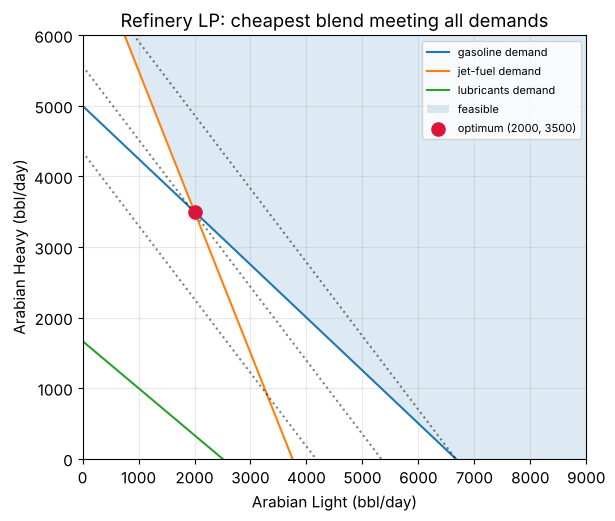

In [4]:
# @title The same refinery problem, drawn
import numpy as np, matplotlib.pyplot as plt
x = np.linspace(0, 9000, 400)
gas = (2000 - 0.30*x)/0.40        # 0.3x1+0.4x2 = 2000
jet = (1500 - 0.40*x)/0.20        # 0.4x1+0.2x2 = 1500
lub = (500  - 0.20*x)/0.30        # 0.2x1+0.3x2 = 500

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(x, gas, label="gasoline demand")
ax.plot(x, jet, label="jet-fuel demand")
ax.plot(x, lub, label="lubricants demand")
# feasible region: on/above every demand line, within the crude bounds
lower = np.maximum.reduce([gas, jet, lub])
ax.fill_between(x, lower, 6000, where=(x<=9000), alpha=0.15, label="feasible")
# cost contours 120x1+115x2
for v in [5e5, 6.4e5, 8e5]:
    ax.plot(x, (v-120*x)/115, "k:", alpha=0.5)
ax.scatter(res.x[0], res.x[1], color="crimson", s=90, zorder=5,
           label=f"optimum ({res.x[0]:.0f}, {res.x[1]:.0f})")
ax.set_xlim(0, 9000); ax.set_ylim(0, 6000)
ax.set_xlabel("Arabian Light (bbl/day)"); ax.set_ylabel("Arabian Heavy (bbl/day)")
ax.set_title("Refinery LP: cheapest blend meeting all demands")
ax.legend(fontsize=8, loc="upper right"); plt.show()

## 4. The same model, indexed

Two crudes and three products fit on a slide; a real refinery has dozens. The cure is
**index notation**, which states the model once for arbitrary size.

- **Sets:** crudes $i \in I$, products $j \in J$.
- **Parameters:** cost $C_i$, availability $A_i$, yield $F_{ij}$ (product $j$ per unit
  crude $i$), demand $D_j$.
- **Variable:** $x_i$ = amount of crude $i$ processed.

$$
\begin{aligned}
\min_{x}\ & \sum_{i\in I} C_i\, x_i && \text{(total crude cost)}\\
\text{s.t.}\ & \sum_{i\in I} F_{ij}\, x_i \ge D_j, && \forall j \in J \quad \text{(meet each demand)}\\
& 0 \le x_i \le A_i, && \forall i \in I \quad \text{(availability)}.
\end{aligned}
$$

Set the data to our two crudes and this collapses back to Section 3 — the same code
now scales to any number of crudes and products just by enlarging the arrays.


In [5]:
# @title Indexed refinery: data-driven, scales to any size
C = np.array([120, 115.0])                 # cost per crude
A_cap = np.array([9000, 6000.0])           # availability
# yield matrix F[i,j]: rows = crudes, cols = [gasoline, jet, lubricants]
F = np.array([[0.30, 0.40, 0.20],
              [0.40, 0.20, 0.30]])
D = np.array([2000, 1500, 500.0])          # demand per product

n = len(C)
res = linprog(C, A_ub=-F.T, b_ub=-D, bounds=[(0, a) for a in A_cap])
print("optimal crude run:", res.x.round(1), " cost $", round(res.fun))
# the same formulation would handle, say, 10 crudes × 6 products unchanged

optimal crude run: [2000. 3500.]  cost $ 642500


## 5. Application: the diet problem

One of the oldest LPs: choose servings of foods to meet nutritional requirements at
**minimum cost**. With foods $i\in I$ and nutrients $j\in J$:

- **Parameters:** cost $C_i$ per serving, nutrient content $A_{ij}$ (amount of nutrient
  $j$ in food $i$), minimum requirement $\text{Nmin}_j$.
- **Variable:** $x_i$ = number of servings of food $i$.

$$
\min_x \sum_i C_i x_i \quad\text{s.t.}\quad \sum_i A_{ij} x_i \ge \text{Nmin}_j \ \ \forall j,
\qquad x_i \ge 0.
$$

A tiny instance: three foods, two nutrient floors (calories and protein).


In [6]:
# @title A small diet problem
foods   = ["oats", "milk", "eggs"]
cost    = np.array([0.50, 0.90, 1.20])          # $ per serving
calories= np.array([110, 160,  80.0])           # kcal per serving
protein = np.array([  4,   8,   6.0])           # g   per serving
Nmin    = {"calories": 2000, "protein": 50}

A_nutri = np.vstack([calories, protein])        # rows: nutrients, cols: foods
b_min   = np.array([Nmin["calories"], Nmin["protein"]])

res = linprog(cost, A_ub=-A_nutri, b_ub=-b_min, bounds=[(0, None)]*3)
print("cheapest diet meeting both floors:  $", round(res.fun, 2), "per day")
for f, s in zip(foods, res.x):
    print(f"  {f:5s}: {s:5.2f} servings")
print(f"  → delivers {calories@res.x:.0f} kcal, {protein@res.x:.0f} g protein")

cheapest diet meeting both floors:  $ 9.09 per day
  oats : 18.18 servings
  milk :  0.00 servings
  eggs :  0.00 servings
  → delivers 2000 kcal, 73 g protein


## 6. Application: the transportation problem

Ship a product from **plants** (each with a supply cap) to **markets** (each with a
demand) at minimum total freight. With plants $i$, markets $j$, unit cost $C_{ij}$:

$$
\begin{aligned}
\min_{x\ge 0}\ & \sum_{i}\sum_{j} C_{ij}\, x_{ij} \\
\text{s.t.}\ & \sum_{j} x_{ij} \le A_i\ \ \forall i \quad\text{(supply)}\\
& \sum_{i} x_{ij} \ge D_j\ \ \forall j \quad\text{(demand)}.
\end{aligned}
$$

Two plants (caps 350, 600 ton/day) serve three markets (demands 325, 300, 275). The
decision variable $x_{ij}$ is a *matrix*, which we flatten for the solver.


In [7]:
# @title Solve the transportation LP
plants  = ["Plant-1", "Plant-2"]
markets = ["Market-A", "Market-B", "Market-C"]
cost = np.array([[2.5, 1.7, 1.8],       # Plant-1 → A,B,C
                 [2.5, 1.8, 1.4]])      # Plant-2 → A,B,C
supply = np.array([350, 600.0])
demand = np.array([325, 300, 275.0])
m, n = cost.shape

# supply rows (<=) and demand rows (>=, written as <= with a sign flip)
A_ub, b_ub = [], []
for i in range(m):
    r = np.zeros(m*n); r[i*n:(i+1)*n] = 1
    A_ub.append(r); b_ub.append(supply[i])
for j in range(n):
    r = np.zeros(m*n); r[j::n] = -1
    A_ub.append(r); b_ub.append(-demand[j])

res = linprog(cost.flatten(), A_ub=A_ub, b_ub=b_ub, bounds=[(0, None)]*(m*n))
X = res.x.reshape(m, n)
print("shipment plan (ton/day):")
print("            " + "  ".join(f"{mk:>8s}" for mk in markets))
for i in range(m):
    print(f"  {plants[i]:9s} " + "  ".join(f"{X[i,j]:8.0f}" for j in range(n)))
print(f"\nminimum total freight cost = ${res.fun:,.2f} per day")

shipment plan (ton/day):
            Market-A  Market-B  Market-C
  Plant-1         50       300         0
  Plant-2        275         0       275

minimum total freight cost = $1,707.50 per day


## 7. The geometry of an LP

Every inequality $a^\top x \le b$ is a half-space; intersecting finitely many gives a
**polytope** — a region with flat faces and sharp corners. Two facts shape everything
that follows:

- The feasible region of an LP is a **convex set**.
- A linear objective is improved by moving in a fixed direction, so if an optimum
  exists it can always be found at a **vertex (extreme point)** of the polytope.

That is why we never need to search the interior: checking the corners suffices.
Consider the standard two-variable example

$$\max\ 4x_1 + 3x_2 \quad\text{s.t.}\quad x_1 + x_2 \le 40,\ \ 2x_1 + x_2 \le 60,\ \ x_1,x_2\ge 0.$$


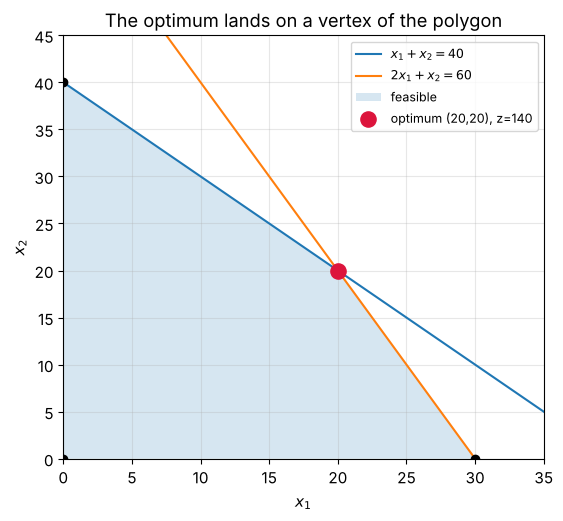

vertex (  20,  20)  z = 140
vertex (   0,  40)  z = 120
vertex (  30,   0)  z = 120
vertex (   0,   0)  z = 0


In [8]:
# @title Feasible polygon, its vertices, and the best corner
import itertools, numpy as np, matplotlib.pyplot as plt

rows = [([1,1],40), ([2,1],60), ([1,0],0), ([0,1],0)]   # 2 constraints + 2 axes
verts = []
for (a1,b1),(a2,b2) in itertools.combinations(rows, 2):
    M = np.array([a1,a2],float)
    if abs(np.linalg.det(M)) < 1e-9: continue
    p = np.linalg.solve(M, [b1,b2])
    if (p >= -1e-9).all() and p[0]+p[1] <= 40+1e-6 and 2*p[0]+p[1] <= 60+1e-6:
        verts.append(p)
verts = np.array(verts)
obj = verts @ [4,3]
best = verts[np.argmax(obj)]

x = np.linspace(0, 35, 200)
fig, ax = plt.subplots(figsize=(6.2, 5.5))
ax.plot(x, 40-x,  label="$x_1+x_2=40$")
ax.plot(x, 60-2*x, label="$2x_1+x_2=60$")
yy = np.minimum(40-x, 60-2*x)
ax.fill_between(x, 0, yy, where=(yy>=0), alpha=0.18, label="feasible")
ax.scatter(verts[:,0], verts[:,1], color="black", zorder=5)
ax.scatter(*best, color="crimson", s=120, zorder=6,
           label=f"optimum ({best[0]:.0f},{best[1]:.0f}), z={obj.max():.0f}")
ax.set_xlim(0,35); ax.set_ylim(0,45)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("The optimum lands on a vertex of the polygon")
ax.legend(fontsize=9); plt.show()
for v,o in zip(verts,obj): print(f"vertex ({v[0]:4.0f},{v[1]:4.0f})  z = {o:.0f}")

## 8. Basic solutions, basic feasible solutions, and extreme points

Vertices have an algebraic twin. Write the constraints in equality form $Ax = b$ with
$m$ equations in $n$ variables ($n > m$ after adding slacks). A **basic solution** is
obtained by:

- choosing $n-m$ variables to set to zero (the **non-basic** variables), and
- solving the remaining $m\times m$ system for the **basic** variables.

If every variable in a basic solution is **non-negative**, it is a **basic feasible
solution (bfs)**. The connection to geometry is exact and is the engine of the
simplex method:

> **Theorem 1.** The feasible region of an LP is convex; if an optimum exists, some
> **extreme point** is optimal.
>
> **Theorem 2.** Every basic feasible solution corresponds to an extreme point of the
> feasible region, and vice versa.

So "search the corners" becomes "enumerate the basic feasible solutions" — a finite,
algebraic task. The example below lists the bfs of our polygon and matches each to a
corner.


In [9]:
# @title Enumerate basic feasible solutions ↔ extreme points
import itertools, numpy as np
# equality form: x1 + x2 + s1      = 40
#                2x1 + x2     + s2 = 60   ; vars (x1,x2,s1,s2) >= 0
A = np.array([[1,1,1,0],[2,1,0,1]], float); b = np.array([40,60.0])
names = ["x1","x2","s1","s2"]; m = 2

print(f"{'basic vars':14s}{'solution':34s}{'feasible?':10s}")
for cols in itertools.combinations(range(4), m):      # choose basic variables
    B = A[:, cols]
    if abs(np.linalg.det(B)) < 1e-9:  continue        # not invertible → no bfs
    xb = np.linalg.solve(B, b)
    full = np.zeros(4); full[list(cols)] = xb
    feas = (full >= -1e-9).all()
    bv = "{"+",".join(names[c] for c in cols)+"}"
    sol = ", ".join(f"{names[k]}={full[k]:.0f}" for k in range(4))
    print(f"{bv:14s}{sol:34s}{'yes (bfs)' if feas else 'no (x<0)'}")

basic vars    solution                          feasible? 
{x1,x2}       x1=20, x2=20, s1=0, s2=0          yes (bfs)
{x1,s1}       x1=30, x2=0, s1=10, s2=0          yes (bfs)
{x1,s2}       x1=40, x2=0, s1=0, s2=-20         no (x<0)
{x2,s1}       x1=0, x2=60, s1=-20, s2=0         no (x<0)
{x2,s2}       x1=0, x2=40, s1=0, s2=20          yes (bfs)
{s1,s2}       x1=0, x2=0, s1=40, s2=60          yes (bfs)


## 9. The simplex method

The simplex method walks from one vertex to an **adjacent** better vertex, improving
the objective at each step, until no neighbour is better — then that vertex is optimal.
In tableau terms:

1. Put the LP in standard form; use the slacks as an initial bfs.
2. **Optimality test:** look at the objective ("row 0"). For a max problem, if every
   non-basic coefficient is non-negative, stop — optimal.
3. **Entering variable:** pick the non-basic variable with the most negative row-0
   coefficient (steepest rate of improvement).
4. **Ratio test:** the entering variable rises until some basic variable hits zero; the
   smallest ratio (RHS ÷ positive entering-column entry) names the **leaving**
   variable, keeping feasibility.
5. **Pivot** (Gaussian elimination) to update the tableau, then go to step 2.

We apply it to a three-product refinery decision:

$$
\begin{aligned}
\max\ & 60x_1 + 30x_2 + 20x_3 \\
\text{s.t.}\ & 8x_1 + 6x_2 + x_3 \le 48 \quad(\text{raw A})\\
& 4x_1 + 2x_2 + 1.5x_3 \le 20 \quad(\text{raw B})\\
& 2x_1 + 1.5x_2 + 0.5x_3 \le 8 \quad(\text{raw C})\\
& x_2 \le 5 \quad(\text{demand cap});\qquad x_1,x_2,x_3 \ge 0.
\end{aligned}
$$


In [10]:
# @title A transparent simplex that prints each pivot
import numpy as np

def simplex_max(c, A, b, var_names=None, verbose=True):
    c, A, b = np.array(c,float), np.array(A,float), np.array(b,float)
    m, n = A.shape
    names = (var_names or [f"x{j+1}" for j in range(n)]) + [f"s{i+1}" for i in range(m)]
    # tableau: [A | I | b] with an objective row z - c^T x = 0
    T = np.zeros((m+1, n+m+1))
    T[:m,:n] = A; T[:m, n:n+m] = np.eye(m); T[:m,-1] = b
    T[m,:n] = -c
    basis = list(range(n, n+m))
    it = 0
    while True:
        j = int(np.argmin(T[m,:n+m]))
        if T[m,j] >= -1e-9:                      # optimality test
            break
        col = T[:m,j]
        ratios = [T[i,-1]/col[i] if col[i] > 1e-9 else np.inf for i in range(m)]
        i = int(np.argmin(ratios))
        if not np.isfinite(ratios[i]):
            print("unbounded"); return None
        it += 1
        if verbose:
            print(f"pivot {it}: {names[j]} enters, {names[basis[i]]} leaves, "
                  f"z = {T[m,-1]:.0f} → ", end="")
        T[i,:] /= T[i,j]
        for k in range(m+1):
            if k != i: T[k,:] -= T[k,j]*T[i,:]
        basis[i] = j
        if verbose: print(f"{T[m,-1]:.0f}")
    x = np.zeros(n+m)
    for i in range(m): x[basis[i]] = T[i,-1]
    return x[:n], T[m,-1], it

c = [60, 30, 20]
A = [[8,6,1],[4,2,1.5],[2,1.5,0.5],[0,1,0]]
b = [48, 20, 8, 5]
x, z, it = simplex_max(c, A, b, ["x1","x2","x3"])
print(f"\noptimum after {it} pivots:  x = {x.round(2)},  z = {z:.0f}")

pivot 1: x1 enters, s3 leaves, z = 0 → 240
pivot 2: x3 enters, s2 leaves, z = 240 → 280

optimum after 2 pivots:  x = [2. 0. 8.],  z = 280


In [11]:
# @title Cross-check against scipy.linprog
res = linprog([-60,-30,-20],
              A_ub=[[8,6,1],[4,2,1.5],[2,1.5,0.5],[0,1,0]],
              b_ub=[48,20,8,5], bounds=[(0,None)]*3)
print("linprog :  x =", res.x.round(2), " z =", round(-res.fun, 0))
print("agreement confirms the hand simplex.")

linprog :  x = [2. 0. 8.]  z = 280.0
agreement confirms the hand simplex.


## 10. Special cases: alternative optima and unbounded LPs

Two outcomes deserve a mental flag.

- **Alternative optima.** If the objective contours are *parallel* to a binding
  constraint, an entire edge of the polygon is optimal — infinitely many solutions tie
  for best. In the simplex tableau this shows up as a non-basic variable with a **zero**
  row-0 coefficient at optimality.
- **Unbounded LP.** If the feasible region stretches to infinity in an improving
  direction, the objective can grow without limit — no optimum exists. In the tableau,
  an entering variable has **no positive entry** in its column, so the ratio test finds
  no leaving variable.

A well-posed process model should be neither accidentally unbounded (a missing
capacity constraint) nor surprised by ties.


In [12]:
# @title An unbounded LP has no finite optimum
# maximize x1 + x2  with only  x1 - x2 <= 1 , x>=0  → grows forever
res = linprog([-1,-1], A_ub=[[1,-1]], b_ub=[1], bounds=[(0,None),(0,None)])
print("status:", res.message)
# and alternative optima: objective parallel to a constraint
#   max x1 + x2  s.t. x1 + x2 <= 4  → every point on that edge is optimal
res2 = linprog([-1,-1], A_ub=[[1,1]], b_ub=[4], bounds=[(0,None),(0,None)])
print("tie example optimum:", res2.x.round(2), " z =", round(-res2.fun,2),
      "(any point with x1+x2=4 is equally optimal)")

status: The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is Feasible)
tie example optimum: [4. 0.]  z = 4.0 (any point with x1+x2=4 is equally optimal)


## 11. Duality and shadow prices

Every LP (the **primal**) has a partner LP (the **dual**) built from the same data.
For a maximization primal with "$\le$" constraints,

$$
\textbf{Primal:}\quad \max\ c^\top x \ \text{ s.t. } Ax \le b,\ x\ge 0
\qquad\Longleftrightarrow\qquad
\textbf{Dual:}\quad \min\ b^\top y \ \text{ s.t. } A^\top y \ge c,\ y\ge 0.
$$

The dual variable $y_i$ attaches to primal constraint $i$ and has a vivid meaning — it
is the **shadow price**, the marginal value of relaxing that constraint by one unit.
Two theorems tie the pair together:

- **Weak duality.** Any feasible primal value is $\le$ any feasible dual value:
  $c^\top x \le b^\top y$. The dual bounds the primal.
- **Strong duality.** If the primal has an optimum, so does the dual, and their
  optimal values are **equal** — no gap.

Take the three-product refinery of Section 9 (keeping the three raw-material limits).
The dual prices each raw material so that producing any product is "worth it":
$\min 48y_1 + 20y_2 + 8y_3$ subject to $A^\top y \ge c$.


In [13]:
# @title Primal, dual, strong duality, and shadow prices
c  = np.array([60, 30, 20.0])
A  = np.array([[8,6,1],[4,2,1.5],[2,1.5,0.5]])
b  = np.array([48, 20, 8.0])

primal = linprog(-c, A_ub=A, b_ub=b, bounds=[(0,None)]*3)
dual   = linprog(b, A_ub=-A.T, b_ub=-c, bounds=[(0,None)]*3)

print(f"primal optimum  z = {-primal.fun:.1f}   x = {primal.x.round(2)}")
print(f"dual   optimum  w = { dual.fun:.1f}   y = {dual.x.round(2)}")
print(f"strong duality:  z == w ?  {np.isclose(-primal.fun, dual.fun)}")

print("\nshadow prices (value of one more unit of each raw material):")
y = -primal.ineqlin.marginals          # scipy reports marginals of the ≤ rows
for name, price in zip(["raw A","raw B","raw C"], y):
    print(f"  {name}: {price:5.2f} $ per unit"
          f"   {'(binding)' if price>1e-6 else '(slack — free to relax)'}")

primal optimum  z = 280.0   x = [2. 0. 8.]
dual   optimum  w = 280.0   y = [ 0. 10. 10.]
strong duality:  z == w ?  True

shadow prices (value of one more unit of each raw material):
  raw A:  0.00 $ per unit   (slack — free to relax)
  raw B: 10.00 $ per unit   (binding)
  raw C: 10.00 $ per unit   (binding)


## 12. Two handy LP reformulations

Some problems look nonlinear but are LPs in disguise once you add variables.

**Minimizing a sum of absolute values.** $\min \sum_k |a_k^\top x + b_k|$ is not
linear, but introduce one $y_k \ge 0$ per term, replace $|{\cdot}|$ by $y_k$ in the
objective, and bound it from both sides:
$$a_k^\top x + b_k \le y_k, \qquad -(a_k^\top x + b_k) \le y_k.$$
Minimizing drives each $y_k$ down to the true absolute value, so the optimum is
unchanged — now a clean LP.

**Minimax.** $\min_x \max_i (c_i^\top x + d_i)$ becomes an LP by adding one scalar $t$:
$$\min_{x,t}\ t \quad\text{s.t.}\quad c_i^\top x + d_i \le t \ \ \forall i.$$
The same trick (flip the signs) turns a *maximin* into an LP. These reformulations are
everywhere in robust process design and control.


In [14]:
# @title LP reformulation of  min 2|x1| + 3|x2|  s.t. x1+2x2 ≤ 4, 2x1 - x2 = 4
# variables: x1, x2 (free), y1, y2 (≥0). objective: 2 y1 + 3 y2
c = [0, 0, 2, 3]
A_ub = [[ 1, 2, 0, 0],      # x1 + 2x2 <= 4
        [ 1, 0,-1, 0],      #  x1 - y1 <= 0   }  together: |x1| <= y1
        [-1, 0,-1, 0],      # -x1 - y1 <= 0   }
        [ 0, 1, 0,-1],      #  x2 - y2 <= 0   }  together: |x2| <= y2
        [ 0,-1, 0,-1]]      # -x2 - y2 <= 0   }
b_ub = [4, 0, 0, 0, 0]
A_eq = [[2, -1, 0, 0]]; b_eq = [4]
res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq,
              bounds=[(None,None),(None,None),(0,None),(0,None)])
x1, x2 = res.x[:2]
print(f"x1 = {x1:.2f},  x2 = {x2:.2f}")
print(f"objective 2|x1| + 3|x2| = {2*abs(x1) + 3*abs(x2):.2f}")

x1 = 2.00,  x2 = -0.00
objective 2|x1| + 3|x2| = 4.00


## 13. Solving LPs in practice

Two families of algorithms dominate, and they are complementary:

- **Simplex** (Dantzig, 1947) walks the vertices of the polytope. Excellent for
  small-to-moderate models and unbeatable for *warm starts* (re-solving after a small
  change).
- **Interior-point / barrier** methods (Karmarkar, 1984) cut *through* the interior in
  a few dozen Newton-like steps, and scale beautifully to very large LPs.

Decades of algorithm-plus-hardware progress have made LPs with millions of variables
routine. In practice you rarely code the method yourself — you call a solver:

- **Python:** `scipy.optimize.linprog` (used throughout this notebook); `PuLP` and
  `Pyomo` for readable algebraic modeling.
- **Industrial solvers:** Gurobi, CPLEX, FICO Xpress; open-source HiGHS, GLPK, CBC.

The modeling skill — turning a process question into variables, an objective, and
constraints — is the part that stays with you; the solver is swappable.


In [15]:
# @title The modeling layer: an LP read almost like its algebra (PuLP if available)
try:
    import pulp
    m = pulp.LpProblem("refinery", pulp.LpMinimize)
    x1 = pulp.LpVariable("Arabian_Light", 0, 9000)
    x2 = pulp.LpVariable("Arabian_Heavy", 0, 6000)
    m += 120*x1 + 115*x2                      # objective
    m += 0.30*x1 + 0.40*x2 >= 2000            # gasoline
    m += 0.40*x1 + 0.20*x2 >= 1500            # jet fuel
    m += 0.20*x1 + 0.30*x2 >= 500             # lubricants
    m.solve(pulp.PULP_CBC_CMD(msg=0))
    print("PuLP optimum: AL =", x1.value(), " AH =", x2.value(),
          " cost $", pulp.value(m.objective))
except ImportError:
    print("PuLP not installed — install with:  pip install pulp")
    print("The scipy.linprog solution from Section 3 is the same optimum.")

PuLP not installed — install with:  pip install pulp
The scipy.linprog solution from Section 3 is the same optimum.


# Part 2 — Tutorial (Hands-on)

Try each **"Your turn"** cell before opening the solution.


## Exercise 1 — Convert an LP to standard form

Convert to standard form (maximization, all equalities, non-negative variables):

$$\min\ 3x_1 + 5x_2 \quad\text{s.t.}\quad x_1 + x_2 \ge 10,\ \ 2x_1 + x_2 \le 16,\ \ x_1,x_2 \ge 0.$$

State the objective rewrite, add a **surplus** to the "$\ge$" row and a **slack** to the
"$\le$" row, and write the equality system $Ax=b$ with columns $(x_1,x_2,e_1,s_2)$.


In [16]:
# @title Exercise 1 — Your turn
# TODO: max -3x1 - 5x2 ;  x1 + x2 - e1 = 10 ;  2x1 + x2 + s2 = 16 ; all vars >= 0
# Build A (2x4) and b, and print them.


In [17]:
# @title Exercise 1 — Solution
import numpy as np
# max z = -3x1 - 5x2  (minimize 3x1+5x2 flipped)
# x1 +  x2 - e1      = 10     (surplus e1 on the >= row)
# 2x1 + x2       + s2 = 16    (slack  s2 on the <= row)
A = np.array([[1,1,-1,0],
              [2,1, 0,1]], float)      # cols: x1, x2, e1, s2
b = np.array([10, 16.0])
print("objective: maximize  -3*x1 - 5*x2")
print("A =\n", A, "\nb =", b)
print("all variables x1, x2, e1, s2 >= 0")

objective: maximize  -3*x1 - 5*x2
A =
 [[ 1.  1. -1.  0.]
 [ 2.  1.  0.  1.]] 
b = [10. 16.]
all variables x1, x2, e1, s2 >= 0


## Exercise 2 — Graphical LP

Plot the feasible region and find the optimum of

$$\max\ 5x_1 + 4x_2 \quad\text{s.t.}\quad 6x_1 + 4x_2 \le 24,\ \ x_1 + 2x_2 \le 6,\ \ x_1,x_2 \ge 0.$$

Enumerate the polygon's vertices, evaluate the objective at each, and mark the winner.


In [18]:
# @title Exercise 2 — Your turn
import numpy as np, matplotlib.pyplot as plt
# constraints: 6x1+4x2<=24 ; x1+2x2<=6 ; x>=0
# TODO: find vertices, evaluate 5x1+4x2, plot region + optimum


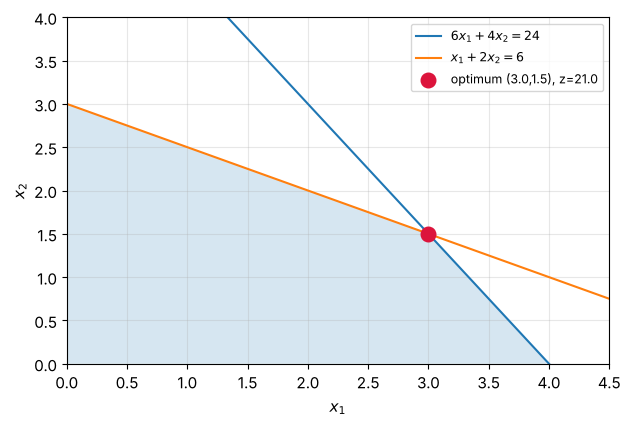

vertex (3.00,1.50)  z=21.00
vertex (4.00,0.00)  z=20.00
vertex (0.00,3.00)  z=12.00
vertex (0.00,0.00)  z=0.00


In [19]:
# @title Exercise 2 — Solution
import itertools, numpy as np, matplotlib.pyplot as plt
rows = [([6,4],24), ([1,2],6), ([1,0],0), ([0,1],0)]
V = []
for (a1,b1),(a2,b2) in itertools.combinations(rows, 2):
    M = np.array([a1,a2],float)
    if abs(np.linalg.det(M)) < 1e-9: continue
    p = np.linalg.solve(M,[b1,b2])
    if (p>=-1e-9).all() and 6*p[0]+4*p[1]<=24+1e-6 and p[0]+2*p[1]<=6+1e-6:
        V.append(p)
V = np.array(V); obj = V@[5,4]; best = V[np.argmax(obj)]

x = np.linspace(0,4.5,200)
fig, ax = plt.subplots()
ax.plot(x,(24-6*x)/4,label="$6x_1+4x_2=24$"); ax.plot(x,(6-x)/2,label="$x_1+2x_2=6$")
yy=np.minimum((24-6*x)/4,(6-x)/2); ax.fill_between(x,0,yy,where=(yy>=0),alpha=0.18)
ax.scatter(*best,color="crimson",s=110,zorder=5,
           label=f"optimum ({best[0]:.1f},{best[1]:.1f}), z={obj.max():.1f}")
ax.set_xlim(0,4.5); ax.set_ylim(0,4); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.legend(fontsize=9); plt.show()
for v,o in zip(V,obj): print(f"vertex ({v[0]:.2f},{v[1]:.2f})  z={o:.2f}")

## Exercise 3 — Solve a refinery variant

Re-solve the two-crude refinery, but a new specification raises **gasoline** demand to
**2500** bbl/day (others unchanged). By how much does the minimum cost rise, and which
constraints are now binding?


In [20]:
# @title Exercise 3 — Your turn
from scipy.optimize import linprog
# TODO: same as Section 3 but b_ub gasoline target = 2500; compare cost


In [21]:
# @title Exercise 3 — Solution
from scipy.optimize import linprog
base = linprog([120,115], A_ub=[[-.3,-.4],[-.4,-.2],[-.2,-.3]],
               b_ub=[-2000,-1500,-500], bounds=[(0,9000),(0,6000)])
new  = linprog([120,115], A_ub=[[-.3,-.4],[-.4,-.2],[-.2,-.3]],
               b_ub=[-2500,-1500,-500], bounds=[(0,9000),(0,6000)])
print(f"base cost : ${base.fun:,.0f}   x = {base.x.round(0)}")
print(f"new  cost : ${new.fun:,.0f}   x = {new.x.round(0)}")
print(f"increase  : ${new.fun-base.fun:,.0f} per day")
x1,x2 = new.x
for nm,a,d in [("gasoline",[.3,.4],2500),("jet",[.4,.2],1500),("lub",[.2,.3],500)]:
    print(f"  {nm:9s}: {a[0]*x1+a[1]*x2:7.1f} vs {d}  "
          f"{'(binding)' if abs(a[0]*x1+a[1]*x2-d)<1 else ''}")

base cost : $642,500   x = [2000. 3500.]
new  cost : $752,500   x = [1000. 5500.]
increase  : $110,000 per day
  gasoline :  2500.0 vs 2500  (binding)
  jet      :  1500.0 vs 1500  (binding)
  lub      :  1850.0 vs 500  


## Exercise 4 — A small transportation problem

Two plants (supply 20 and 30) serve two markets (demand 25 and 25). Unit costs:

| | Market-A | Market-B |
|---|---|---|
| Plant-1 | 8 | 6 |
| Plant-2 | 5 | 9 |

Find the minimum-cost shipment plan and total cost.


In [22]:
# @title Exercise 4 — Your turn
from scipy.optimize import linprog
import numpy as np
# cost = [[8,6],[5,9]] ; supply=[20,30] ; demand=[25,25]
# TODO: build supply (<=) and demand (>=) rows, solve, reshape


In [23]:
# @title Exercise 4 — Solution
from scipy.optimize import linprog
import numpy as np
cost = np.array([[8,6],[5,9.0]]); supply=[20,30.0]; demand=[25,25.0]
m,n = cost.shape; A_ub=[]; b_ub=[]
for i in range(m):
    r=np.zeros(m*n); r[i*n:(i+1)*n]=1; A_ub.append(r); b_ub.append(supply[i])
for j in range(n):
    r=np.zeros(m*n); r[j::n]=-1; A_ub.append(r); b_ub.append(-demand[j])
res=linprog(cost.flatten(),A_ub=A_ub,b_ub=b_ub,bounds=[(0,None)]*(m*n))
X=res.x.reshape(m,n)
print("shipments:\n", X.round(0))
print(f"total cost = ${res.fun:,.0f}")

shipments:
 [[ 0. 20.]
 [25.  5.]]
total cost = $290


## Exercise 5 — Run the simplex

Use the `simplex_max` function from Section 9 to solve

$$\max\ 3x_1 + 2x_2 \quad\text{s.t.}\quad x_1 + x_2 \le 4,\ \ x_1 + 3x_2 \le 6,\ \ x_1,x_2\ge 0,$$

and confirm the answer with `linprog`. How many pivots did it take?


In [24]:
# @title Exercise 5 — Your turn
# Re-run the Section 9 cell first so simplex_max is defined.
# TODO: simplex_max([3,2], [[1,1],[1,3]], [4,6], ["x1","x2"])


In [25]:
# @title Exercise 5 — Solution
# (ensure the Section 9 cell defining simplex_max has been run)
x, z, it = simplex_max([3,2], [[1,1],[1,3]], [4,6], ["x1","x2"])
print(f"\nsimplex : x = {x.round(2)}, z = {z:.1f}, pivots = {it}")
from scipy.optimize import linprog
r = linprog([-3,-2], A_ub=[[1,1],[1,3]], b_ub=[4,6], bounds=[(0,None)]*2)
print(f"linprog : x = {r.x.round(2)}, z = {-r.fun:.1f}")

pivot 1: x1 enters, s1 leaves, z = 0 → 12

simplex : x = [4. 0.], z = 12.0, pivots = 1
linprog : x = [4. 0.], z = 12.0


## Exercise 6 — Build and interpret the dual

For the primal
$$\max\ 5x_1 + 4x_2 \quad\text{s.t.}\quad 6x_1 + 4x_2 \le 24,\ \ x_1 + 2x_2 \le 6,\ \ x\ge0,$$
write the dual $\min 24y_1 + 6y_2$ s.t. $A^\top y \ge c$, solve both, verify strong
duality, and interpret the shadow prices $y_1, y_2$.


In [26]:
# @title Exercise 6 — Your turn
from scipy.optimize import linprog
import numpy as np
# c=[5,4]; A=[[6,4],[1,2]]; b=[24,6]
# TODO: solve primal (max) and dual (min 24y1+6y2 s.t. A^T y >= c); compare values


In [27]:
# @title Exercise 6 — Solution
from scipy.optimize import linprog
import numpy as np
c=np.array([5,4.0]); A=np.array([[6,4],[1,2.0]]); b=np.array([24,6.0])
P=linprog(-c,A_ub=A,b_ub=b,bounds=[(0,None)]*2)
D=linprog(b,A_ub=-A.T,b_ub=-c,bounds=[(0,None)]*2)
print(f"primal z = {-P.fun:.2f}  at x = {P.x.round(2)}")
print(f"dual   w = { D.fun:.2f}  at y = {D.x.round(2)}")
print("strong duality holds:", np.isclose(-P.fun, D.fun))
y=-P.ineqlin.marginals
print(f"shadow prices: y1 = {y[0]:.2f} (per unit of RHS-1), y2 = {y[1]:.2f} (per unit of RHS-2)")
print("→ one extra unit of a binding resource raises the optimum by its shadow price.")

primal z = 21.00  at x = [3.  1.5]
dual   w = 21.00  at y = [0.75 0.5 ]
strong duality holds: True
shadow prices: y1 = 0.75 (per unit of RHS-1), y2 = 0.50 (per unit of RHS-2)
→ one extra unit of a binding resource raises the optimum by its shadow price.


## Summary — key takeaways

- An **LP** has a linear objective, linear constraints, and continuous variables. It is
  convex, so a local optimum is global.
- Any LP folds into **standard form** by four moves: flip max/min, add **slacks** to
  "$\le$", **surpluses** to "$\ge$", and split **free** variables.
- Classic chemical-engineering LPs — **refinery planning, the diet problem, the
  transportation problem** — share the same skeleton: parameters, variables, an
  objective, and resource/demand constraints. Index notation lets one model scale to
  any size.
- The feasible region is a **polytope**; an optimum sits at a **vertex**, which
  algebraically is a **basic feasible solution**. The **simplex** method hops between
  adjacent vertices until none is better.
- Watch for **alternative optima** (ties) and **unbounded** models (a missing
  constraint).
- **Duality** gives every LP a partner whose variables are **shadow prices** — the
  marginal value of each resource — and **strong duality** guarantees matching optimal
  values.
- In practice, model the problem clearly and let a solver (**`scipy.linprog`**, PuLP,
  Gurobi, …) run **simplex** or an **interior-point** method.

---

*Module 2 of CHE 581 — Process Optimization. Prepared by Abdulelah S. Alshehri,
Department of Chemical Engineering, King Saud University.*
